# RAG sencillo con BGE-M3 + Chroma + LangGraph

En el notebook anterior aprendimos a **buscar** textos parecidos a una pregunta.
Ahora damos un paso más y construimos un **RAG** (*Retrieval-Augmented Generation*):

1. **Recuperar**: buscamos en la base de datos vectorial los textos más relacionados con la pregunta.
2. **Generar**: le pasamos a un modelo de lenguaje (LLM) la pregunta **y** esos textos, y le pedimos que responda **solo** con esa información.

Para organizar los pasos usaremos **LangGraph**, una librería para construir "flujos" de IA como si fueran un diagrama.

> Notebook para aprender, no para producción: priorizamos que se entienda cada pieza.

## 0. Instalación

Después de instalar, **reinicia la sesión** (menú *Entorno de ejecución → Reiniciar sesión*) y continúa desde la siguiente celda.
Pueden salir avisos de dependencias en rojo: son inofensivos para este notebook.

Recomendado: activa la GPU (*Entorno de ejecución → Cambiar tipo de entorno → GPU T4*). BGE-M3 es más grande que el modelo del notebook anterior (~2,3 GB).

In [4]:
%pip install sentence-transformers chromadb langgraph langchain-openai python-dotenv langchain-core langchain-text-splitters pypdf python-docx

Note: you may need to restart the kernel to use updated packages.


## 1. Configurar el modelo de lenguaje (LLM)

Usamos **Gemini** a través de su API "compatible con OpenAI". La ventaja: si mañana cambiamos a otro proveedor
(o al proxy del centro), solo hay que cambiar `BASE_URL`, `MODELO` y la clave.


In [5]:
import os
from dotenv import load_dotenv

load_dotenv()

API_KEY = os.getenv("GEMINI_API_KEY")

if API_KEY:
    print("¡API Key cargada correctamente!")
else:
    print("No se pudo encontrar la API Key. Revisa que el archivo .env esté en la ruta correcta.")

¡API Key cargada correctamente!


In [ ]:
from langchain_openai import ChatOpenAI

# try:
#     from google.colab import userdata
#     API_KEY = userdata.get("GEMINI_API_KEY")
# except Exception:
#     from getpass import getpass
#     API_KEY = getpass("Introduce tu API key de Gemini: ")

BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"   # o la URL del proxy del centro
MODELO   = "gemini-3.5-flash-lite"

llm = ChatOpenAI(model=MODELO, api_key=API_KEY, base_url=BASE_URL, temperature=0)

# Prueba rápida de que el LLM responde
print(llm.invoke("Di 'hola' en gallego, solo la palabra.").content)

Ola


## 2. Nuestros documentos: carga y *chunking*

Ahora los documentos ya no están escritos a mano en una lista: los leemos de la carpeta **`docs/`** (que está junto a este notebook).
Admite **.txt, .md, .pdf y .docx**, y puede tener subcarpetas.

Como un PDF o un DOCX puede ser muy largo, lo partimos en trozos (**chunks**) de unos 900 caracteres con un solapamiento de 150,
para que una idea que cae en el borde entre dos trozos no se pierda. Cada chunk guarda en sus **metadatos** de qué archivo
(`source`, `doc_key`) y de qué página (`page`, solo en PDF) viene, y un identificador único (`chunk_id`) que usaremos en Chroma y para citar.

> Si la carpeta `docs/` está vacía, la celda siguiente crea en ella los 12 documentos de ejemplo (en castellano y en gallego) para que el notebook funcione desde el principio.
> Después puedes borrarlos y poner los tuyos: apuntes, normativa del ciclo, horarios...

In [7]:
import logging
from pathlib import Path
from typing import List

import docx  # pip install python-docx
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pypdf import PdfReader

logger = logging.getLogger(__name__)

DOCS_DIR = Path.cwd() / "docs"   # en un notebook no existe __file__: usamos la carpeta de trabajo
SUPPORTED_EXTS = {".txt", ".md", ".pdf", ".docx"}


def _meta(path: Path, **extra) -> dict:
    return {"source": str(path), "doc_key": path.name, **extra}


def load_txt_md(path: Path) -> List[Document]:
    try:
        txt = path.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        txt = path.read_text(encoding="cp1252", errors="replace")
    if not txt.strip():
        return []
    return [Document(page_content=txt, metadata=_meta(path))]


def load_pdf(path: Path) -> List[Document]:
    reader = PdfReader(str(path))
    if reader.is_encrypted:
        reader.decrypt("")  # PDFs con contraseña vacía
    docs: List[Document] = []
    for i, page in enumerate(reader.pages):
        txt = page.extract_text() or ""
        if txt.strip():
            docs.append(Document(page_content=txt, metadata=_meta(path, page=i + 1)))
    return docs


def load_docx(path: Path) -> List[Document]:
    d = docx.Document(str(path))
    parts = [p.text for p in d.paragraphs if p.text.strip()]
    for table in d.tables:
        for row in table.rows:
            cells = [c.text.strip() for c in row.cells if c.text.strip()]
            if cells:
                parts.append(" | ".join(cells))
    txt = "\n".join(parts).strip()
    if not txt:
        return []
    return [Document(page_content=txt, metadata=_meta(path))]


LOADERS = {".txt": load_txt_md, ".md": load_txt_md, ".pdf": load_pdf, ".docx": load_docx}


def load_file(path: Path) -> List[Document]:
    loader = LOADERS.get(path.suffix.lower())
    if loader is None:
        return []
    try:
        return loader(path)
    except Exception as e:
        logger.warning("No se pudo leer %s: %s", path, e)
        return []


def chunkenizar(docs_dir: Path = DOCS_DIR, chunk_size: int = 900, chunk_overlap: int = 150) -> List[Document]:
    if chunk_overlap >= chunk_size:
        raise ValueError("chunk_overlap debe ser menor que chunk_size")

    docs_d = Path(docs_dir).resolve()
    files = sorted(
        p for p in docs_d.rglob("*")
        if p.is_file()
        and p.suffix.lower() in SUPPORTED_EXTS
        and not p.name.startswith(("~$", "."))   # ignora temporales de Word y ocultos
    )
    if not files:
        logger.warning("No hay documentos en %s (pdf/docx/txt/md).", docs_d)
        return []

    raw_docs: List[Document] = []
    for p in files:
        raw_docs.extend(load_file(p))
    if not raw_docs:
        logger.warning("No se pudo extraer texto útil de los documentos.")
        return []

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=["\n\n", "\n", ". ", " ", ""],
        add_start_index=True,
    )
    chunks = splitter.split_documents(raw_docs)

    for i, c in enumerate(chunks):
        pagina = f":p{c.metadata['page']}" if "page" in c.metadata else ""
        c.metadata["chunk_id"] = f"{Path(c.metadata['doc_key']).stem}{pagina}:c{i}"

    print(f"{len(files)} archivos -> {len(raw_docs)} documentos/páginas -> {len(chunks)} chunks")
    return chunks

In [21]:
# Documentos de ejemplo: solo se crean si docs/ está vacía
EJEMPLOS = {
    "cocina_paella.txt":     "La paella valenciana se cocina con arroz, pollo, conejo, judía verde y azafrán.",
    "cocina_tortilla.txt":   "Para una buena tortilla de patatas, fríe las patatas a fuego lento antes de mezclarlas con el huevo.",
    "cocina_polbo.txt":      "O polbo á feira sérvese sobre madeira con aceite de oliva, sal grosa e pemento.",
    "deporte_depor.txt":     "El Deportivo de La Coruña ganó la Liga en la temporada 1999-2000.",
    "deporte_correr.txt":    "Correr tres veces por semana mejora la resistencia cardiovascular.",
    "deporte_triple.txt":    "En baloncesto, un triple vale tres puntos si se lanza desde fuera de la línea.",
    "tecnologia_python.txt": "Python es un lenguaje de programación muy usado en ciencia de datos e inteligencia artificial.",
    "tecnologia_gpu.txt":    "Una GPU acelera el entrenamiento de redes neuronales porque hace muchas operaciones en paralelo.",
    "tecnologia_git.txt":    "Git permite guardar versiones del código y trabajar en equipo sin pisarse los cambios.",
    "viajes_santiago.txt":   "Santiago de Compostela es el final del Camino de Santiago y su catedral es Patrimonio de la Humanidad.",
    "viajes_equipaje.txt":   "Para volar con equipaje de mano, revisa las medidas máximas que permite la aerolínea.",
    "viajes_cies.txt":       "Para visitar as Illas Cíes no verán hai que solicitar autorización á Xunta e reservar o barco.",
}

DOCS_DIR.mkdir(exist_ok=True)
if not any(p.is_file() for p in DOCS_DIR.rglob("*")):
    for nombre, texto in EJEMPLOS.items():
        (DOCS_DIR / nombre).write_text(texto, encoding="utf-8")
    print(f"Creados {len(EJEMPLOS)} documentos de ejemplo en {DOCS_DIR}")
else:
    print(f"Usando los documentos que ya hay en {DOCS_DIR}")

Usando los documentos que ya hay en c:\Users\aroa.torresdominguez\Documents\MOIA\docs


In [9]:
chunks = chunkenizar(DOCS_DIR, chunk_size=900, chunk_overlap=150)

textos = [c.page_content for c in chunks]

# Vemos los primeros chunks y sus metadatos
for c in chunks[:5]:
    print(c.metadata["chunk_id"], "|", c.page_content[:80].replace("\n", " "))

12 archivos -> 12 documentos/páginas -> 12 chunks
cocina_paella:c0 | La paella valenciana se cocina con arroz, pollo, conejo, judía verde y azafrán.
cocina_polbo:c1 | O polbo á feira sérvese sobre madeira con aceite de oliva, sal grosa e pemento.
cocina_tortilla:c2 | Para una buena tortilla de patatas, fríe las patatas a fuego lento antes de mezc
deporte_correr:c3 | Correr tres veces por semana mejora la resistencia cardiovascular.
deporte_depor:c4 | El Deportivo de La Coruña ganó la Liga en la temporada 1999-2000.


## 3. Vectorizar con BGE-M3

**BGE-M3** (de BAAI) es un modelo de la familia BERT (basado en XLM-RoBERTa) entrenado específicamente para **recuperación**:
encontrar el texto que responde a una pregunta, no solo frases que dicen lo mismo.

- Multilingüe (más de 100 idiomas).
- Admite textos largos (hasta 8192 tokens).
- Cada texto se convierte en un vector de **1024** números.

In [10]:
from sentence_transformers import SentenceTransformer

modelo_emb = SentenceTransformer("BAAI/bge-m3")   # la primera vez tarda: descarga ~2,3 GB

# Con muchos chunks conviene ir por lotes y ver el progreso
vectores = modelo_emb.encode(textos, normalize_embeddings=True, batch_size=16, show_progress_bar=True)
print("Forma de la matriz:", vectores.shape)   # (número de chunks, 1024)

c:\Users\aroa.torresdominguez\Documents\MOIA\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 1/1 [00:00<00:00,  1.45it/s]

Forma de la matriz: (12, 1024)


## 4. Guardar en Chroma

Igual que en el notebook anterior: id, vector, texto y metadatos. Ahora:
- el **id** es el `chunk_id` de cada trozo,
- los **metadatos** dicen de qué archivo y página viene (para poder citar la fuente),
- añadimos **por lotes**, porque Chroma tiene un máximo de elementos por llamada y un PDF largo puede dar miles de chunks.

In [11]:
import chromadb

cliente = chromadb.PersistentClient(path="./chroma_rag")

if "apuntes_rag" in [c.name for c in cliente.list_collections()]:
    cliente.delete_collection("apuntes_rag")

coleccion = cliente.create_collection(name="apuntes_rag", metadata={"hnsw:space": "cosine"})

# Chroma solo admite metadatos str/int/float/bool: nos quedamos con los que nos interesan
def metadatos_chroma(c):
    m = {"source": c.metadata["source"], "doc_key": c.metadata["doc_key"],
         "start_index": c.metadata.get("start_index", 0)}
    if "page" in c.metadata:
        m["page"] = c.metadata["page"]
    return m

LOTE = 1000
for i in range(0, len(chunks), LOTE):
    coleccion.add(
        ids=[c.metadata["chunk_id"] for c in chunks[i:i + LOTE]],
        embeddings=vectores[i:i + LOTE].tolist(),
        documents=textos[i:i + LOTE],
        metadatas=[metadatos_chroma(c) for c in chunks[i:i + LOTE]],
    )
print("Chunks guardados:", coleccion.count())

Chunks guardados: 12


## 5. El RAG como un grafo (LangGraph)

LangGraph organiza el programa con tres ideas:

| Concepto | Qué es | En nuestro RAG |
|---|---|---|
| **Estado** | Una "ficha" con los datos que van pasando de un paso a otro | `pregunta`, `documentos`, `respuesta` |
| **Nodos** | Funciones: reciben el estado y devuelven lo que actualizan | `recuperar` y `generar` |
| **Aristas** | Flechas que dicen qué nodo va después | INICIO → recuperar → generar → FIN |

### 5.1 El estado

In [12]:
from typing import TypedDict

class Estado(TypedDict):
    pregunta: str
    documentos: list[dict]   # los chunks que encuentra la búsqueda
    respuesta: str           # lo que contesta el LLM

### 5.2 Nodo 1: recuperar

Vectoriza la pregunta **con el mismo modelo** que los chunks y pide a Chroma los `K` más parecidos.
Además del texto, recuperamos los **metadatos** para saber de qué archivo y página sale cada trozo.

In [13]:
K = 3   # cuántos chunks le pasamos al LLM

def recuperar(estado: Estado) -> dict:
    vector_pregunta = modelo_emb.encode([estado["pregunta"]], normalize_embeddings=True).tolist()
    res = coleccion.query(query_embeddings=vector_pregunta, n_results=K,
                          include=["documents", "metadatas", "distances"])

    encontrados = []
    for doc_id, texto, meta, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0]):
        fuente = meta["doc_key"] + (f", pág. {meta['page']}" if "page" in meta else "")
        encontrados.append({"id": doc_id, "texto": texto, "fuente": fuente, "similitud": round(1 - dist, 2)})

    return {"documentos": encontrados}

### 5.3 Nodo 2: generar

Construimos el **prompt**: instrucciones + chunks recuperados + pregunta.
Las instrucciones son clave: le pedimos que **no invente** y que **cite** de qué chunk saca cada dato.
A cada chunk le ponemos delante su id y su fuente (archivo y página).

In [14]:
INSTRUCCIONES = """Eres un asistente que responde preguntas usando ÚNICAMENTE los documentos proporcionados.
- Si la respuesta no está en los documentos, di: "No tengo esa información en los documentos."
- Indica entre corchetes el id del documento que usas, tal como aparece, por ejemplo [apuntes:p3:c12].
- Responde en el mismo idioma en que está escrita la pregunta, de forma breve."""

def generar(estado: Estado) -> dict:
    contexto = "\n\n".join(f"[{d['id']}] (fuente: {d['fuente']})\n{d['texto']}" for d in estado["documentos"])

    mensajes = [
        ("system", INSTRUCCIONES),
        ("human", f"DOCUMENTOS:\n{contexto}\n\nPREGUNTA: {estado['pregunta']}"),
    ]
    respuesta = llm.invoke(mensajes)
    return {"respuesta": respuesta.content}

### 5.4 Montar el grafo

In [15]:
from langgraph.graph import StateGraph, START, END

grafo = StateGraph(Estado)

grafo.add_node("recuperar", recuperar)
grafo.add_node("generar", generar)

grafo.add_edge(START, "recuperar")
grafo.add_edge("recuperar", "generar")
grafo.add_edge("generar", END)

rag = grafo.compile()

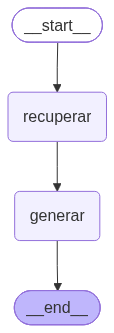

In [16]:
# Dibujamos el grafo para verlo
from IPython.display import Image, display
try:
    display(Image(rag.get_graph().draw_mermaid_png()))
except Exception:
    print(rag.get_graph().draw_mermaid())

## 6. Hacer preguntas

`rag.invoke(...)` recibe el estado inicial (solo la pregunta) y devuelve el estado final, ya relleno.
Mostramos también qué chunks se recuperaron y de qué archivo vienen, para ver **de dónde sale** la respuesta.

> Las preguntas de ejemplo funcionan con los documentos de ejemplo. Si has puesto tus propios documentos en `docs/`, cámbialas.

In [17]:
def preguntar(pregunta):
    estado_final = rag.invoke({"pregunta": pregunta})

    print(f" {pregunta}\n")
    print("Chunks recuperados:")
    for d in estado_final["documentos"]:
        print(f"   {d['similitud']:.2f} | [{d['id']}] ({d['fuente']}) {d['texto'][:100].replace(chr(10), ' ')}")
    print(f"\n{estado_final['respuesta']}")
    print("-" * 80)

In [18]:
preguntar("¿Qué ingredientes lleva la paella?")
preguntar("¿En qué año fue campeón de Liga el Dépor?")
preguntar("Que necesito para ir ás Illas Cíes en agosto?")   # pregunta en gallego

 ¿Qué ingredientes lleva la paella?

Chunks recuperados:
   0.69 | [cocina_paella:c0] (cocina_paella.txt) La paella valenciana se cocina con arroz, pollo, conejo, judía verde y azafrán.
   0.46 | [cocina_polbo:c1] (cocina_polbo.txt) O polbo á feira sérvese sobre madeira con aceite de oliva, sal grosa e pemento.
   0.42 | [cocina_tortilla:c2] (cocina_tortilla.txt) Para una buena tortilla de patatas, fríe las patatas a fuego lento antes de mezclarlas con el huevo.

La paella valenciana se cocina con arroz, pollo, conejo, judía verde y azafrán [cocina_paella:c0].
--------------------------------------------------------------------------------
 ¿En qué año fue campeón de Liga el Dépor?

Chunks recuperados:
   0.53 | [deporte_depor:c4] (deporte_depor.txt) El Deportivo de La Coruña ganó la Liga en la temporada 1999-2000.
   0.27 | [viajes_santiago:c11] (viajes_santiago.txt) Santiago de Compostela es el final del Camino de Santiago y su catedral es Patrimonio de la Humanida
   0.21 | [deporte

### ¿Y si preguntamos algo que no está en los documentos?

Un buen RAG debe **reconocer que no lo sabe** en lugar de inventar. Fíjate también en la similitud: es más baja.

In [19]:
preguntar("¿Cuál es la capital de Australia?")

 ¿Cuál es la capital de Australia?

Chunks recuperados:
   0.30 | [viajes_santiago:c11] (viajes_santiago.txt) Santiago de Compostela es el final del Camino de Santiago y su catedral es Patrimonio de la Humanida
   0.23 | [deporte_correr:c3] (deporte_correr.txt) Correr tres veces por semana mejora la resistencia cardiovascular.
   0.23 | [deporte_triple:c5] (deporte_triple.txt) En baloncesto, un triple vale tres puntos si se lanza desde fuera de la línea.

No tengo esa información en los documentos.
--------------------------------------------------------------------------------


### Comparación: el mismo LLM sin RAG

Sin documentos, el modelo responde con lo que "recuerda" de su entrenamiento: puede acertar, pero no sabemos de dónde lo saca
ni puede conocer información privada o reciente (por ejemplo, la normativa de un centro).

In [20]:
print(llm.invoke("¿Qué necesito para visitar las Islas Cíes en verano? Responde en una frase.").content)

Para visitar las Islas Cíes en verano necesitas solicitar la autorización previa y gratuita de la Xunta de Galicia, comprar el billete de barco con una naviera autorizada y llevar tu documento de identidad.


## 7. Para practicar

1. **Cambia `K`** a 1 y a 6. ¿Mejora o empeora la respuesta? ¿Qué pasa si le das documentos irrelevantes al LLM?
2. **Quita las instrucciones** de "no inventes" y vuelve a hacer la pregunta sobre Australia. ¿Qué cambia?
3. **Añade tus propios documentos** a `docs/` (por ejemplo, el horario o las normas del ciclo en PDF o DOCX), vuelve a ejecutar desde la sección 2 y hazle preguntas.
4. **Cambia `chunk_size` y `chunk_overlap`** (por ejemplo 300/50 y 2000/300). ¿Recupera mejor con trozos pequeños o grandes?
5. **Añade un umbral**: en `recuperar`, descarta los chunks con similitud menor que 0,4. Si no queda ninguno, ¿qué debería hacer el LLM?
